## How to run

The data are not included: CRSP data may not be redistributed under the WRDS licence. To run the notebook:

1. Download the files listed in `data/raw/manifest.csv` from WRDS (the README says how) and put them in `data/raw/`.
2. In this folder, run `pip install -r requirements.txt`.
3. The final-test cells check against the saved test run, `data/processed/step8_results.pkl`, which is not included
   either. Create it once with `python src/checks.py crsp && python src/returns.py && python src/signals.py && python src/test_period.py run`.
4. Open the notebook from this folder and choose **Restart & Run All** (Kernel menu).

The first code cell checks this setup and stops with a message naming anything that is missing.

# Overnight vs intraday returns in SPY, QQQ and IWM

This notebook runs the whole pipeline from the raw data in `data/raw/` to the final test, in order: data
acquisition, cleaning, strategy and backtest. Each stage calls the code in `src/` that does the work and then shows
its key output; every stage also writes a detailed write-up to `reports/`.

The whole notebook takes about a minute.

It runs from the files in `data/raw/` and first checks them against the manifest.

In [1]:
import hashlib, importlib.util, sys
from pathlib import Path

ROOT = Path.cwd()
missing = [f"{d}/" for d in ["src", "data/raw"] if not (ROOT / d).is_dir()]
if missing:
    raise FileNotFoundError(f"Missing next to the notebook in {ROOT}: {', '.join(missing)}. Open notebook.ipynb "
                            "from the folder that holds src/, data/ and requirements.txt.")
packages = ["pandas", "pyarrow", "numpy", "exchange_calendars", "statsmodels", "scipy", "matplotlib"]
missing = [p for p in packages if importlib.util.find_spec(p) is None]
if missing:
    raise ModuleNotFoundError(f"Missing packages: {', '.join(missing)}. Run pip install -r requirements.txt in this "
                              "kernel's environment, then Restart & Run All.")

import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
from config import CHOSEN_SIGNAL, END, RAW, SAMPLES

def show_section(report, heading):
    sections = (ROOT / "reports" / report).read_text().split("\n## ")
    display(Markdown("#### " + next(s for s in sections if s.startswith(heading))))

print("samples:", SAMPLES, "| end:", END, "| frozen signal:", CHOSEN_SIGNAL)

samples: {'train': ('1993-01-01', '2012-12-31'), 'validation': ('2013-01-01', '2018-12-31'), 'test': ('2019-01-01', '2025-12-31')} | end: 2025-12-31 | frozen signal: sig_c


## Data acquisition

All data come from WRDS, exported through the WRDS query forms and saved in `data/raw/`:

| file | source | content |
|---|---|---|
| `crsp_daily.csv` | CRSP v2 daily stock file | SPY, QQQ, IWM by PERMNO (84398, 86755, 88222): open, high, low, close, bid, ask, total and ex-dividend return, volume, cumulative price factor |
| `wrds_vix.csv` | CBOE indexes on WRDS | VIX daily close |
| `wrds_tbill3m.csv` | Federal Reserve Board H.15 on WRDS | 3-month T-bill, secondary market (`dtb3`), annual % on a discount basis, up to 2025-02-13 |
| `fred_dtb3_extension.csv` | FRED | the same `DTB3` series from 2025-02-12 to 2025-12-31, because the WRDS copy stops at 2025-02-13 |

The files are not included in this repository because of the WRDS licence. The first check is that the files in
`data/raw/` are exactly the ones recorded in the manifest.

In [2]:
manifest = pd.read_csv(RAW / "manifest.csv")
manifest["sha256_matches"] = [hashlib.sha256((RAW / f).read_bytes()).hexdigest() == h
                              for f, h in zip(manifest["file"], manifest["sha256"])]
assert manifest["sha256_matches"].all(), "data/raw does not match the manifest"
manifest[["file", "source", "rows", "first_date", "last_date", "sha256_matches"]]

,file,source,rows,first_date,last_date,sha256_matches
0,crsp_daily.csv,WRDS CRSP,21478,1993-01-29,2025-12-31,True
1,wrds_vix.csv,WRDS CBOE,8534,1993-01-04,2026-09-30,True
2,wrds_tbill3m.csv,WRDS FRB H.15,11732,1993-01-01,2025-02-13,True
3,fred_dtb3_extension.csv,FRED,221,2025-02-12,2025-12-31,True


In [3]:
from data_layer import load_prices

# CRSP rows are licensed, so only counts and date ranges are shown
load_prices("crsp").groupby("ticker")["date"].agg(["min", "max", "size"])

,min,max,size
ticker,,,
IWM,2000-05-26,2025-12-31,6438
QQQ,1999-03-10,2025-12-31,6746
SPY,1993-01-29,2025-12-31,8288


## Cleaning

`checks.py` checks the panel against the NYSE calendar, duplicates, missing and stale opens, OHLC consistency,
extreme moves (each matched to a market event), dividends, splits, half-days, crossed quotes, VIX gaps and the
risk-free rate. Nothing is silently dropped: each issue becomes a flag column, and later steps decide what to exclude.

`returns.py` then splits each day into an overnight leg (previous close to open, dividends included) and an
intraday leg (open to close), adds the daily T-bill return to the overnight leg, and checks that the two legs
multiply back to the CRSP close-to-close total return.

In [4]:
import checks
checks.report("crsp")
flagged = pd.read_parquet(ROOT / "data/processed/prices_crsp_flagged.parquet")
flagged.filter(like="flag_").groupby(flagged["ticker"]).sum()

wrote reports/step2_data_checks.md


,flag_stale_open,flag_extreme,flag_reversal,flag_ohlc,flag_bad_price,flag_ex_div,flag_split,flag_half_day,flag_first_row
ticker,,,,,,,,,
IWM,89,44,12,0,0,103,1,58,1
QQQ,72,94,19,0,1,86,1,60,1
SPY,140,31,9,0,4,129,0,73,1


In [5]:
show_section("step2_data_checks.md", "10. Decisions")

#### 10. Decisions

| Issue | Handling |
|---|---|
| Duplicates | Exact duplicate rows in the CRSP and VIX exports, one copy kept |
| Close | `DlyPrc`, the bid/ask midpoint on the one no-trade day (SPY 1997-03-31) |
| Missing opens | Flagged, those days have no overnight or intraday return |
| Stale opens | Flagged, 14% of SPY days in 1993 and under 2% after 1998 |
| Extreme moves and reversals | All large moves and all 40 reversals fall on known market events, so they are kept |
| Dividends | Backed out of `ret - retx`, the open falls by most of the dividend on ex-dates |
| Crossed quotes | Not used as costs, the backtest carries the last valid spread |
| Risk-free rate | T-bill converted to a daily return, all of it on the overnight leg. The WRDS Fama-French rf is rounded to whole basis points, so it is not used |


In [ ]:
import returns
returns.report("crsp")
show_section("step3_returns.md", "Checks")

## Strategy

Each night the strategy decides whether to hold the ETF from the close to the next open. A decision for the
night after day t uses only data up to the close of day t-1, so a market-on-close order can be placed in time.

- `sig_a`: the previous day's intraday return was negative
- `sig_b`: the previous day's intraday return was in its worst 20% of the 252 days before it
- `sig_c`: VIX at the previous close was above its median of the 252 days before it
- `sig_ac` = `sig_a` and `sig_c`, `sig_bc` = `sig_b` and `sig_c`

These five candidates were fixed before any returns were examined. The look-ahead tests recompute the signals with
the data cut at random dates (truncation) or with everything after the cut replaced by noise (perturbation); a
deliberately leaky version is included to show the tests can catch a leak.

In [ ]:
import signals
signals.report("crsp")
show_section("step4_signals.md", "Look-ahead tests")

The hypotheses are tested on the training sample only (1993-2012): H1 compares overnight and intraday excess
returns (Newey-West), H2 asks whether the signals predict the next night's return (regressions and on/off gaps,
Holm-adjusted across 15 tests), and H3 compares SPY with IWM (stacked regression, Driscoll-Kraay errors).

In [8]:
import hypothesis_tests
hypothesis_tests.report("crsp")
show_section("step5_tests.md", "Summary")

wrote reports/step5_tests.md


#### Summary

Supported means p < 0.05 both on all days and without flagged days.

| hypothesis | ticker | estimate | p_all_days | p_clean | verdict |
|---|---|---|---|---|---|
| H1 overnight beats intraday | SPY | 3.25 bp a day | 0.043 | 0.034 | supported |
| H1 overnight beats intraday | QQQ | 8.82 bp a day | 0.003 | 0.008 | supported |
| H1 overnight beats intraday | IWM | 5.62 bp a day | 0.032 | 0.014 | supported |
| H1 gap smaller after 2008 | SPY | -4.17 bp a day | 0.315 | 0.336 | not supported |
| H1 gap smaller after 2008 | QQQ | -12.30 bp a day | 0.032 | 0.054 | mixed |
| H1 gap smaller after 2008 | IWM | -5.55 bp a day | 0.322 | 0.435 | not supported |
| H2 signal nights earn more | SPY | 0 of 5 signals after Holm | 1.000 | 1.000 | not supported |
| H2 signal nights earn more | QQQ | 0 of 5 signals after Holm | 0.621 | 0.932 | not supported |
| H2 signal nights earn more | IWM | 0 of 5 signals after Holm | 1.000 | 1.000 | not supported |
| H3 IWM reacts differently from SPY | SPY vs IWM | 3 slopes jointly | 0.181 | 0.245 | not supported |


## Backtest

`backtest.py` treats each day as two legs that are either fully in the ETF or in cash (no leverage). Cash earns the
T-bill on the overnight leg. Every change of position is a trade, so holding one night costs two trades. Costs are
charged per trade at 0, 1, 2, 5 and 10 bp, and at the CRSP closing quoted half-spread.

Strategies per ETF: buy and hold, always intraday, always overnight, and overnight only when each signal is on, plus
a placebo of 1,000 random sets of the same number of nights.

The train period (1993-2012) is used for design, validation (2013-2018) picks one signal with a rule fixed in
advance, and the test period (2019-2025) evaluates the frozen choice.

In [9]:
import backtest
backtest.report("crsp")
show_section("step6_backtest.md", "Breakeven cost per trade (bp)")

wrote reports/step6_backtest.md


#### Breakeven cost per trade (bp)

Cost at which the annual return falls to cash or to buy-and-hold, `-` means below it even at zero cost.

| strategy | SPY vs_cash | QQQ vs_cash | IWM vs_cash | SPY vs_buy_hold | QQQ vs_buy_hold | IWM vs_buy_hold |
|---|---|---|---|---|---|---|
| intraday | - | - | - | - | - | - |
| overnight | 1.34 | 1.23 | 1.65 | 0.42 | 2.44 | 0.82 |
| on_sig_a | 1.77 | 2.75 | 0.62 | - | 5.25 | - |
| on_sig_b | 2.35 | 4.65 | 1.35 | - | 10.91 | - |
| on_sig_c | 1.46 | 0.57 | 0.27 | - | 3.46 | - |
| on_sig_ac | 1.38 | 3.52 | - | - | 8.83 | - |
| on_sig_bc | 1.66 | 4.73 | 1.35 | - | 15.51 | - |


In [10]:
import validation
chosen = validation.report("crsp")
print("validation picks:", chosen, "| frozen in config.py:", CHOSEN_SIGNAL)
assert chosen == CHOSEN_SIGNAL
show_section("step7_validation.md", "Chosen signal")

wrote reports/step7_validation.md
validation picks: sig_c | frozen in config.py: sig_c


#### Chosen signal: `sig_c`

Rule fixed before the run: best Sharpe at 1 bp per trade averaged over SPY, QQQ and IWM, ties at two decimals go to the signal that trades less.

| strategy | SPY | QQQ | IWM | mean_sharpe | mean_trades_per_yr | rank |
|---|---|---|---|---|---|---|
| on_sig_c | 0.581 | 0.721 | 0.482 | 0.595 | 231.306 | 1 |
| on_sig_ac | 0.399 | 0.614 | 0.209 | 0.407 | 119.714 | 2 |
| on_sig_bc | 0.530 | 0.571 | -0.002 | 0.366 | 71.205 | 3 |
| on_sig_b | 0.325 | 0.450 | 0.110 | 0.295 | 103.804 | 4 |
| on_sig_a | 0.234 | 0.480 | -0.044 | 0.223 | 228.858 | 5 |

Sharpe at 1 bp, train vs validation:

| strategy | SPY train | QQQ train | IWM train | SPY validation | QQQ validation | IWM validation |
|---|---|---|---|---|---|---|
| buy_hold | 0.33 | -0.04 | 0.29 | 0.91 | 1.01 | 0.61 |
| intraday | -0.33 | -0.49 | -0.29 | -0.14 | -0.08 | -0.26 |
| on_sig_a | 0.27 | 0.42 | -0.04 | 0.23 | 0.48 | -0.04 |
| on_sig_ac | 0.10 | 0.33 | -0.20 | 0.40 | 0.61 | 0.21 |
| on_sig_b | 0.25 | 0.45 | 0.08 | 0.33 | 0.45 | 0.11 |
| on_sig_bc | 0.11 | 0.30 | 0.06 | 0.53 | 0.57 | -0.00 |
| on_sig_c | 0.17 | -0.00 | -0.07 | 0.58 | 0.72 | 0.48 |
| overnight | 0.21 | 0.15 | 0.32 | 0.39 | 0.76 | 0.41 |


### Key results: in-sample vs out-of-sample

The table recomputes buy and hold, always overnight, always intraday and the frozen signal in every sample with the
same engine. Train is where the strategy was designed, validation where the signal was chosen, and test is the
out-of-sample period (see the README for why the test is not a clean holdout).

In [11]:
from backtest import backtest as run_backtest

keep, samples = ["buy_hold", "overnight", "intraday", f"on_{CHOSEN_SIGNAL}"], ["train", "validation", "test"]
key = pd.concat([run_backtest("crsp", s, [CHOSEN_SIGNAL])[0].assign(sample=s) for s in samples])
key = key[key["strategy"].isin(keep) & key["cost"].isin(["0 bp", "1 bp"])]
key = key.astype({"strategy": pd.CategoricalDtype(keep, ordered=True), "sample": pd.CategoricalDtype(samples, ordered=True)})
key.pivot_table(index=["ticker", "strategy"], columns=["sample", "cost"],
                values=["cum_ret_%", "sharpe", "max_dd_%"], observed=True).round(2)

cum_ret_%                                            max_dd_%                                        sharpe                                   
sample               train         validation            test            train        validation          test         train       validation        test      
cost                  0 bp    1 bp       0 bp    1 bp    0 bp    1 bp     0 bp   1 bp       0 bp   1 bp   0 bp   1 bp   0 bp  1 bp       0 bp  1 bp  0 bp  1 bp
ticker strategy                                                                                                                                                
IWM    buy_hold      98.75   98.71      72.37   72.34  101.00  100.96   -59.03 -59.03     -26.80 -26.80 -41.07 -41.07   0.29  0.29       0.61  0.61  0.41  0.41
       overnight    220.05   78.69      67.99   24.20  211.83  119.30   -28.67 -30.20     -18.92 -24.65 -28.82 -29.34   0.70  0.32       1.02  0.41  0.92  0.61
       intraday     -24.19  -57.67       6.12  -21.54  -22.10  -45.21   -54.42 -67.81     -28.93 -35.22 -47.59 -61.35  -0.07 -0.29       0.10 -0.26 -0.23 -0.49
       on_sig_c      30.23    2.92      42.70   24.23  100.92   70.77   -28.67 -30.20      -9.84 -11.64 -28.68 -29.14   0.11 -0.07       0.82  0.48  0.58  0.42
QQQ    buy_hold     -40.06  -40.07     152.93  152.88  316.65  316.56   -82.98 -82.98     -22.79 -22.79 -35.12 -35.12  -0.04 -0.04       1.01  1.01  0.85  0.85
       overnight    187.95   51.16     111.06   56.04  125.49   58.58   -30.56 -36.12     -11.94 -15.41 -27.30 -30.83   0.47  0.15       1.29  0.76  0.67  0.34
       intraday     -72.82  -85.73      23.94   -8.37  123.31   57.05   -84.94 -90.26     -24.04 -25.92 -23.87 -27.96  -0.31 -0.49       0.29 -0.08  0.56  0.29
       on_sig_c      52.36   16.35      67.90   46.17   62.48   38.10   -31.20 -35.61      -9.28  -9.31 -27.07 -27.38   0.16 -0.00       0.99  0.72  0.39  0.21
SPY    buy_hold     325.53  325.44      97.74   97.70  203.57  203.51   -55.20 -55.20     -19.34 -19.34 -33.70 -33.70   0.33  0.33       0.91  0.91  0.77  0.77
       overnight    533.21  144.29      64.76   21.81   90.59   34.03   -32.00 -38.19     -13.06 -16.84 -29.41 -29.76   0.69  0.21       1.05  0.39  0.57  0.18
       intraday      19.09  -54.06      24.13   -8.23   92.50   35.38   -52.99 -73.56     -23.21 -26.65 -14.17 -20.16  -0.04 -0.33       0.34 -0.14  0.53  0.18
       on_sig_c     247.31  118.94      48.50   29.28   53.84   30.75   -29.01 -36.89      -7.07  -8.32 -29.17 -29.46   0.43  0.17       0.92  0.58  0.35  0.16

### Final test (2019-2025)

`test_period.py` ran the test once with the signal, engine, costs and test code frozen, and saved the results to
`data/processed/step8_results.pkl`. That file is the lock: `test_period.py run` refuses to run while it exists, and
this notebook never writes to it. The cell below recomputes every saved table (engine checks, the backtest for each
test window, breakevens, placebo, spreads and the H4 tests) from the current code and checks that each value matches
the saved run, so nothing here is a new decision.


In [12]:
import pickle
import numpy as np
import test_period as tp
from backtest import check_engine, load_sample
from hypothesis_tests import load_train

assert tp.RESULTS.exists(), f"{tp.RESULTS.name} is missing: the saved test run is required"
lock_sha = hashlib.sha256(tp.RESULTS.read_bytes()).hexdigest()
saved = pickle.load(open(tp.RESULTS, "rb"))
assert saved["signal"] == CHOSEN_SIGNAL
print(f"saved run: commit {saved['commit']}, {saved['run_utc']} UTC, signal {saved['signal']}")

# the saved run predates a renaming of some labels and columns
RENAME = {"spread est.": "spread", "breakeven_vs_cash_bp": "vs_cash", "breakeven_vs_buy_hold_bp": "vs_buy_hold"}

def compare(name, new, old):
    old = old.rename(columns=RENAME).replace(RENAME)
    cols = [c for c in new.columns if c in old.columns]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(new[c])]
    a, b = new[cols].reset_index(drop=True), old[cols].reset_index(drop=True)
    assert len(a) == len(b), f"{name}: row count differs"
    assert a.drop(columns=num).astype(str).equals(b.drop(columns=num).astype(str)), f"{name}: labels differ"
    x, y = a[num].to_numpy(float), b[num].to_numpy(float)
    assert (np.isnan(x) == np.isnan(y)).all(), f"{name}: missing values differ"
    d = np.abs(x - y)[~np.isnan(x)]
    return {"table": name, "values": d.size, "max_abs_diff": d.max() if d.size else 0.0}

eng = check_engine(*load_sample("crsp", "test"), "test")
rows = [{"table": "engine check", "values": len(eng),
         "max_abs_diff": np.abs(eng["engine"].to_numpy() - saved["engine_check"]["engine"].to_numpy()).max()}]
for p, w in tp.PERIODS.items():
    new, old = run_backtest("crsp", "test", [CHOSEN_SIGNAL], w), saved["backtest"][p]
    rows += [compare(f"{p} {name}", new[i], old[i]) for i, name in [(0, "performance"), (1, "breakeven"), (2, "placebo"), (4, "spread by year")]]

train, test = load_train("crsp"), tp.load_test("crsp")
for exclude in [False, True]:
    label = "without flagged days" if exclude else "all days"
    rows += [compare(f"H4 {k} ({label})", v, saved["h4"][exclude][k]) for k, v in tp.h4(train, test, exclude).items()]

check = pd.DataFrame(rows)
assert (check["max_abs_diff"] < 1e-9).all(), "the recomputed test does not match the saved run"
assert hashlib.sha256(tp.RESULTS.read_bytes()).hexdigest() == lock_sha
print(f"all {check['values'].sum()} values in {len(check)} tables match the saved run; the lock file is unchanged")
check

saved run: commit e5c09e1, 2026-10-19 15:58 UTC, signal sig_c


all 1991 values in 21 tables match the saved run; the lock file is unchanged


,table,values,max_abs_diff
0,engine check,4,0.0
1,2019-2025 performance,432,0.0
2,2019-2025 breakeven,9,0.0
3,2019-2025 placebo,21,0.0
4,2019-2025 spread by year,21,0.0
5,2019-2020 performance,432,0.0
6,2019-2020 breakeven,9,0.0
7,2019-2020 placebo,21,0.0
8,2019-2020 spread by year,6,0.0
9,2021+ performance,432,0.0


In [13]:
show_section("step8_test.md", "Placebo")

#### Placebo

Percentile of the signal against 1000 random sets of the same number of nights, at 0 bp.

| ticker | signal | cost | nights | ann_ret_% | placebo_median_ann_% | ann_percentile | sharpe | placebo_median_sharpe | placebo_5_95_sharpe | sharpe_percentile |
|---|---|---|---|---|---|---|---|---|---|---|
| SPY | sig_c | 0 bp | 813 | 6.36 | 5.88 | 57.80 | 0.35 | 0.39 | -0.08 / 0.92 | 44.90 |
| QQQ | sig_c | 0 bp | 813 | 7.20 | 7.07 | 51.60 | 0.39 | 0.45 | 0.00 / 0.92 | 42.00 |
| IWM | sig_c | 0 bp | 813 | 10.51 | 9.42 | 63.20 | 0.58 | 0.62 | 0.14 / 1.10 | 43.80 |

### Robustness and cumulative returns

`robustness.py` runs descriptive checks on the whole sample (by era, without the best 1% of days, weekends, a
walk-forward re-pick, bootstrap intervals for Sharpe, flagged days, signal timing and volatility-scaled sizing).
None of them feeds back into a decision.

wrote reports/step9_robustness.md


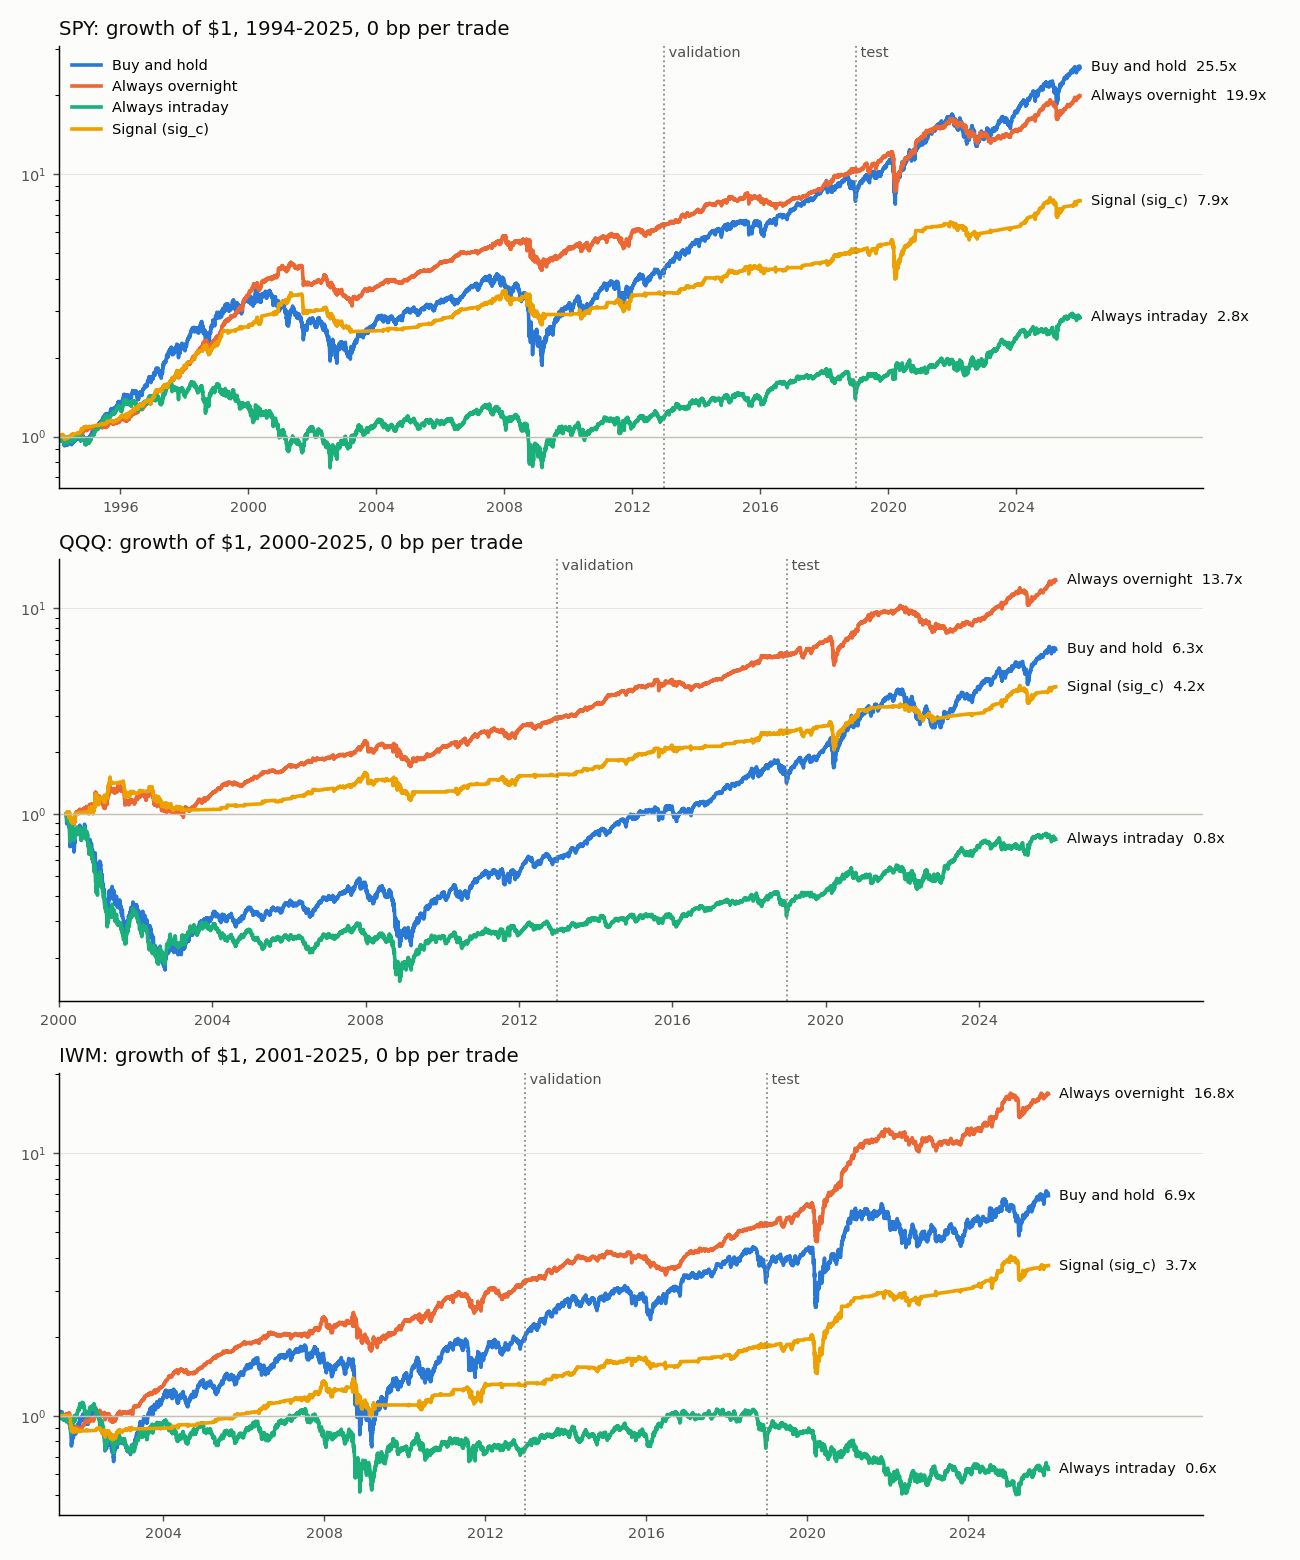

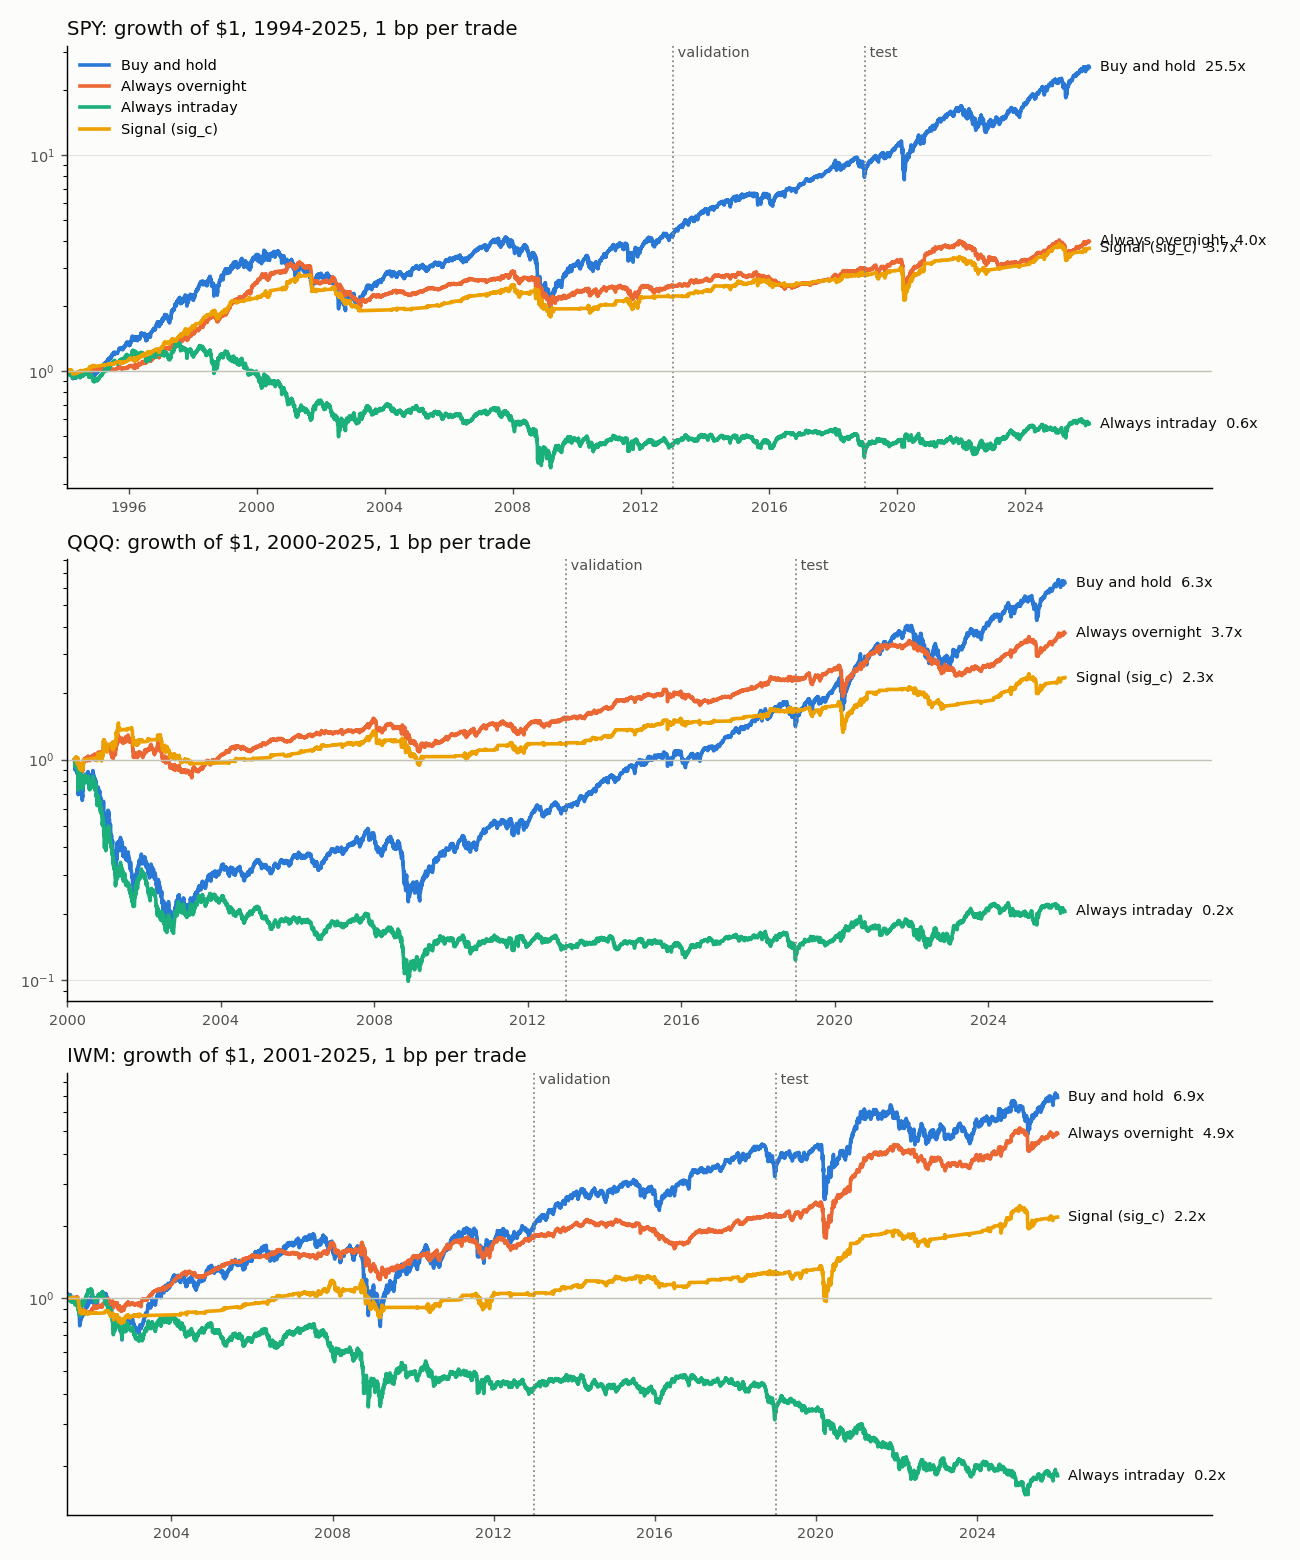

In [14]:
import robustness
robustness.report("crsp")
for cost in [0, 1]:
    display(Image(str(ROOT / f"reports/figures/step9_cumulative_{cost}bp.png"), width=700))

In [15]:
show_section("step9_robustness.md", "5. Bootstrap")

#### 5. Bootstrap 95% intervals for Sharpe at 1 bp (21-day blocks, 2000 draws)

| ticker | sample | item | sharpe | ci_low | ci_high | excludes_0 |
|---|---|---|---|---|---|---|
| SPY | train | Buy and hold | 0.33 | -0.06 | 0.72 |  |
| SPY | train | Always overnight | 0.21 | -0.16 | 0.63 |  |
| SPY | train | Always intraday | -0.33 | -0.72 | 0.04 |  |
| SPY | train | Signal (sig_c) | 0.17 | -0.20 | 0.59 |  |
| SPY | train | Always overnight minus Buy and hold | -0.12 | -0.51 | 0.27 |  |
| SPY | train | Signal (sig_c) minus Always overnight | -0.05 | -0.25 | 0.15 |  |
| SPY | train | Signal (sig_c) minus Buy and hold | -0.16 | -0.57 | 0.25 |  |
| SPY | validation | Buy and hold | 0.91 | 0.19 | 1.67 | yes |
| SPY | validation | Always overnight | 0.39 | -0.18 | 1.06 |  |
| SPY | validation | Always intraday | -0.14 | -0.88 | 0.64 |  |
| SPY | validation | Signal (sig_c) | 0.58 | 0.07 | 1.19 | yes |
| SPY | validation | Always overnight minus Buy and hold | -0.51 | -1.25 | 0.25 |  |
| SPY | validation | Signal (sig_c) minus Always overnight | 0.19 | -0.19 | 0.56 |  |
| SPY | validation | Signal (sig_c) minus Buy and hold | -0.32 | -1.08 | 0.45 |  |
| SPY | test | Buy and hold | 0.77 | 0.05 | 1.58 | yes |
| SPY | test | Always overnight | 0.18 | -0.61 | 1.12 |  |
| SPY | test | Always intraday | 0.18 | -0.43 | 0.73 |  |
| SPY | test | Signal (sig_c) | 0.16 | -0.62 | 1.16 |  |
| SPY | test | Always overnight minus Buy and hold | -0.59 | -1.04 | -0.04 | yes |
| SPY | test | Signal (sig_c) minus Always overnight | -0.02 | -0.29 | 0.32 |  |
| SPY | test | Signal (sig_c) minus Buy and hold | -0.61 | -1.11 | 0.01 |  |
| QQQ | train | Buy and hold | -0.04 | -0.51 | 0.44 |  |
| QQQ | train | Always overnight | 0.15 | -0.30 | 0.60 |  |
| QQQ | train | Always intraday | -0.49 | -0.97 | -0.02 | yes |
| QQQ | train | Signal (sig_c) | -0.00 | -0.47 | 0.45 |  |
| QQQ | train | Always overnight minus Buy and hold | 0.19 | -0.28 | 0.65 |  |
| QQQ | train | Signal (sig_c) minus Always overnight | -0.15 | -0.41 | 0.10 |  |
| QQQ | train | Signal (sig_c) minus Buy and hold | 0.04 | -0.49 | 0.55 |  |
| QQQ | validation | Buy and hold | 1.01 | 0.31 | 1.78 | yes |
| QQQ | validation | Always overnight | 0.76 | 0.18 | 1.44 | yes |
| QQQ | validation | Always intraday | -0.08 | -0.77 | 0.66 |  |
| QQQ | validation | Signal (sig_c) | 0.72 | 0.18 | 1.37 | yes |
| QQQ | validation | Always overnight minus Buy and hold | -0.25 | -0.95 | 0.48 |  |
| QQQ | validation | Signal (sig_c) minus Always overnight | -0.04 | -0.37 | 0.33 |  |
| QQQ | validation | Signal (sig_c) minus Buy and hold | -0.29 | -1.05 | 0.51 |  |
| QQQ | test | Buy and hold | 0.85 | 0.19 | 1.60 | yes |
| QQQ | test | Always overnight | 0.34 | -0.35 | 1.15 |  |
| QQQ | test | Always intraday | 0.29 | -0.33 | 0.89 |  |
| QQQ | test | Signal (sig_c) | 0.21 | -0.46 | 1.06 |  |
| QQQ | test | Always overnight minus Buy and hold | -0.52 | -1.02 | 0.04 |  |
| QQQ | test | Signal (sig_c) minus Always overnight | -0.12 | -0.45 | 0.23 |  |
| QQQ | test | Signal (sig_c) minus Buy and hold | -0.64 | -1.21 | 0.04 |  |
| IWM | train | Buy and hold | 0.29 | -0.22 | 0.84 |  |
| IWM | train | Always overnight | 0.32 | -0.17 | 0.85 |  |
| IWM | train | Always intraday | -0.29 | -0.78 | 0.21 |  |
| IWM | train | Signal (sig_c) | -0.07 | -0.55 | 0.40 |  |
| IWM | train | Always overnight minus Buy and hold | 0.02 | -0.46 | 0.52 |  |
| IWM | train | Signal (sig_c) minus Always overnight | -0.39 | -0.69 | -0.11 | yes |
| IWM | train | Signal (sig_c) minus Buy and hold | -0.37 | -0.90 | 0.17 |  |
| IWM | validation | Buy and hold | 0.61 | -0.14 | 1.37 |  |
| IWM | validation | Always overnight | 0.41 | -0.29 | 1.18 |  |
| IWM | validation | Always intraday | -0.26 | -1.05 | 0.51 |  |
| IWM | validation | Signal (sig_c) | 0.48 | -0.16 | 1.18 |  |
| IWM | validation | Always overnight minus Buy and hold | -0.20 | -1.01 | 0.64 |  |
| IWM | validation | Signal (sig_c) minus Always overnight | 0.07 | -0.45 | 0.57 |  |
| IWM | validation | Signal (sig_c) minus Buy and hold | -0.13 | -0.93 | 0.66 |  |
| IWM | test | Buy and hold | 0.41 | -0.30 | 1.13 |  |
| IWM | test | Always overnight | 0.61 | -0.18 | 1.42 |  |
| IWM | test | Always intraday | -0.49 | -1.10 | 0.14 |  |
| IWM | test | Signal (sig_c) | 0.42 | -0.39 | 1.25 |  |
| IWM | test | Always overnight minus Buy and hold | 0.19 | -0.37 | 0.74 |  |
| IWM | test | Signal (sig_c) minus Always overnight | -0.19 | -0.53 | 0.19 |  |
| IWM | test | Signal (sig_c) minus Buy and hold | 0.00 | -0.62 | 0.66 |  |


In [16]:
assert hashlib.sha256(tp.RESULTS.read_bytes()).hexdigest() == lock_sha
print("lock file unchanged:", tp.RESULTS.name, lock_sha[:12])

lock file unchanged: step8_results.pkl 4f585804fb72
